# Proyecto Portafolio | Simulación PYME Residuos: Optimización de Márgenes

## Optimización de Márgenes y Simulación de Escenarios Comerciales
### Auditoría de rentabilidad y modelos de contingencia en gestión de residuos


### Contexto del Proyecto

Este proyecto nace de un caso real en una pyme del sector de la gestión de residuos no peligrosos. Aunque la normativa europea y las exigencias legales han dado un vuelco total al sector en la última década, la forma de fijar los precios en muchas de estas empresas se ha quedado anclada en el pasado.

Tradicionalmente, las tarifas se deciden a ojo: pesa más la relación comercial o la costumbre que los costes reales de cada operación. ¿El resultado? Cuando el combustible se dispara o cambian las condiciones, las revisiones de precios se hacen de forma puramente reactiva y sin ninguna base analítica transparente.

Para mantener el foco y la precisión, esta simulación se centra en la operativa de dos flujos de materiales clave: **plástico y cartón**.



### Objetivo del Análisis

El propósito de este análisis es evidenciar —mediante datos y simulaciones visuales— los fallos estructurales del modelo de precios actual y el riesgo financiero que supone para la empresa tomar decisiones basadas en la intuición en lugar de en los costes reales.

Frente a la improvisación, el objetivo es construir un modelo de costes transparente que permita justificar y ajustar las tarifas de forma equilibrada frente a las fluctuaciones reales del mercado, blindando la rentabilidad sin espantar a los clientes clave.




## Contexto del Negocio: ¿Qué hace esta empresa?

Para entender este modelo de datos, hay que comprender primero la operativa real detrás de los números. La PYME objeto de este análisis opera como un **gestor intermedio de residuos industriales**:

* **Origen B2B:** La empresa no trabaja con particulares. Todos los residuos proceden exclusivamente de otras empresas productoras que necesitan dar salida legal a sus subproductos o sobrantes.
* **Logística de transporte:** El residuo se desplaza desde la nave de la empresa productora hasta las instalaciones de nuestra PYME mediante un contenedor específico.
* **Proceso en planta:** Una vez en nuestras instalaciones, el residuo se descarga, se clasifica, se separa y se compacta en **balas** para optimizar su volumen, quedando listo para ser vendido a un **gestor final** (el reciclador definitivo).
* **Trazabilidad legal (El documento DI):** Cada movimiento está amparado obligatoriamente por un **Documento de Identificación (DI)**, un registro oficial con una estructura estricta marcada por la ley que debe acompañar físicamente al residuo en cada traslado.
* **La complejidad operativa (Residuos "Mezcla"):** No todos los contenedores llegan "limpios". Algunos transportan residuos heterogéneos. En la base de datos, esto se identifica añadiendo la palabra **"mezcla"** al nombre del residuo. Esta etiqueta es clave a nivel de negocio, ya que procesar un contenedor mezclado requiere un esfuerzo operativo mayor y, por tanto, su coste de gestión es considerablemente más alto que el de un residuo homogéneo.






## Arquitectura del Cuaderno y los Datos

Para facilitar la lectura y el enfoque analítico de este proyecto, hay que tener en cuenta las siguientes consideraciones técnicas sobre los datos y la estructura del código:

* **Datos autocontenidos:** Todo el conjunto de datos está simulado y generado directamente dentro del propio cuaderno, por lo que no es necesario cargar ficheros externos.
* **Foco en el modelado (Sin limpieza innecesaria):** La simulación ha sido diseñada con pautas estrictas para garantizar la integridad (sin *NaNs* ni duplicados irrelevantes). Esto permite omitir el preprocesamiento repetitivo y centrar el esfuerzo en la **lógica de negocio, el cálculo de costes y la estrategia de precios**.
* **Estructura espejo del mundo real:** El diseño de las tablas replica fielmente un entorno de gestión real. El núcleo operativo pivota sobre la tabla nodriza de **Documentos de Identificación (DIs)** —el elemento crítico para la pyme—, sobre la cual se van incorporando secuencialmente las capas de costes, consumos, combustibles y precios de venta.

## Esquema del Pipeline de Datos y Lógica de Agregación

Para mantener un control absoluto sobre el modelo y evitar un escenario de "caja negra", las transformaciones y cruces de datos siguen una **jerarquía operativa secuencial** estructurada en tres niveles:

---

### 1. Nivel Granular: El Documento de Identificación (`DI`)
* **Lógica de negocio:** Cada residuo transportado requiere obligatoriamente su propio DI. Por tanto, si un mismo contenedor lleva varios tipos de residuos (mezcla), a ese único traslado se le asignan múltiples DIs.
* **Cálculo:** A este nivel tan detallado asociamos los **costes de gestión e ingresos por venta del propio material**, dependiendo del tipo de residuo específico de cada registro.

---

### 2. Nivel Logístico: El Viaje (`id_viaje`)
* **Lógica de negocio:** Un porte o viaje físico puede englobar más de un DI (cuando el contenedor lleva residuos diversos).
* **Cálculo:** Una vez resuelta la parte del material, agrupamos la información por `id_viaje` para integrar los **costes logísticos del transporte** (kilometraje, combustible, maniobras y conductor) y calcular el coste e ingreso total real de cada traslado.

---

### 3. Nivel Estratégico: Nave y Mes (`id_nave`, `mes`)
* **Lógica de negocio:** La relación comercial con el cliente no se evalúa viaje a viaje, sino de forma consolidada mes a mes por cada una de sus instalaciones.
* **Cálculo:** Agrupamos los resultados por `mes` e `id_nave`. En esta etapa final incorporamos los **ingresos fijos por alquiler mensual de contenedores** y la bonificación correspondiente, obteniendo el **beneficio neto total**.
* **Resultado final:** Este dataset consolidado sirve de base para generar el **mapa de calor**, una herramienta visual clave para que la dirección identifique de un vistazo qué naves y meses son realmente rentables.

#**Bloque 1:** Generación de la base de datos simulada

In [95]:
# 1 Importación de librerías
import sqlite3
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import random
import numpy as np
from datetime import datetime, timedelta

In [96]:
# 2 Simulación de datos

random.seed(42) # Semilla fija para reproducibilidad

# =========================================================================
# 1. CREACIÓN AUTOMÁTICA DEL ENTORNO DE DATOS
# =========================================================================


    # -------------------------------------------------------------------------
    # Tabla: Costes Básicos (Mano de obra y fijos de nave)
    # -------------------------------------------------------------------------
costes=pd.DataFrame([
    {
    "id_costes": 1,
    "fecha_inicio": "2026-01-01",
    "fecha_fin": None,            # Tarifa vigente sin fecha de caducidad explícita
    "coste_general_hora": 8.5,    # Amortizaciones, seguros e indirectos de estructura
    "coste_trabajador_hora": 14.0 # Coste de personal directo asignado
    }
])

# -------------------------------------------------------------------------
# Tabla: Precios del Transporte (Controlamos las variaciones del precio del petróleo)
# -------------------------------------------------------------------------
pr_combustibles=pd.DataFrame([
    {"id_pr_combustible": 1, "fecha_inicio": "2026-01-01", "fecha_fin": "2026-02-28", "precio_diesel": 1.65, "precio_gasoil": 1.40},
    {"id_pr_combustible": 2, "fecha_inicio": "2026-03-01", "fecha_fin": None,         "precio_diesel": 1.78, "precio_gasoil": 1.52}
])

# -------------------------------------------------------------------------
# Tabla: Consumos Básicos (Consumo de camiones y toros a ojo)
# -------------------------------------------------------------------------
consumos=pd.DataFrame([
    {
    "id_consumo": 1,
    "l_gasoil_hora": 1.0,  # Estimación en planta según ratios operacionales del toro
    "l_diesel_km": 0.3     # Media de consumo de la flota de camiones por kilómetro
    }
])

# -------------------------------------------------------------------------
# Tabla distancias (Ida y vuelta + 2Km maniobras, grúa...)
# -------------------------------------------------------------------------
# Convertimos la distancia a tipo str para evitar agregaciones o medias accidentales en Pandas
poblacion=pd.DataFrame([
    {"id_poblacion": 1, "poblacion": "Población 1", "distancia": "25.0", "total_km": 2 * 25.0 + 2},
    {"id_poblacion": 2, "poblacion": "Población 2", "distancia": "15.0", "total_km": 2 * 15.0 + 2},
    {"id_poblacion": 3, "poblacion": "Población 3", "distancia": "10.0", "total_km": 2 * 10.0 + 2},
    {"id_poblacion": 4, "poblacion": "Población 4", "distancia": "35.0", "total_km": 2 * 35.0 + 2}
])

# -------------------------------------------------------------------------
# Tabla clientes
# -------------------------------------------------------------------------
clientes=pd.DataFrame([
    {"CIF": "A11111111", "razon_social": "Empresa 1"},
    {"CIF": "B22222222", "razon_social": "Empresa 2"},
    {"CIF": "C33333333", "razon_social": "Empresa 3"},
    {"CIF": "D44444444", "razon_social": "Empresa 4"},
    {"CIF": "E55555555", "razon_social": "Empresa 5"},
])

# -------------------------------------------------------------------------
# Tabla naves: Para separar las distintas delegaciones o ubicaciones físicas de un mismo cliente
# -------------------------------------------------------------------------
naves=pd.DataFrame( [
    {"id_nave": 1, "CIF": "A11111111", "alias_nave": "Nave 1", "poblacion": "Población 1", "NIMA": "2800001111", "num_productor": "P-01"},
    {"id_nave": 2, "CIF": "B22222222", "alias_nave": "Nave 2A", "poblacion": "Población 4", "NIMA": "2800002222", "num_productor": "P-02"},
    {"id_nave": 3, "CIF": "B22222222", "alias_nave": "Nave 2B", "poblacion": "Población 2", "NIMA": "2800002223", "num_productor": "P-03"},
    {"id_nave": 4, "CIF": "C33333333", "alias_nave": "Nave 3A", "poblacion": "Población 3", "NIMA": "2800003333", "num_productor": "P-04"},
    {"id_nave": 5, "CIF": "C33333333", "alias_nave": "Nave 3B", "poblacion": "Población 3", "NIMA": "2800003333", "num_productor": "P-04"},
    {"id_nave": 6, "CIF": "C33333333", "alias_nave": "Nave 3C", "poblacion": "Población 3", "NIMA": "2800003333", "num_productor": "P-04"},
    {"id_nave": 7, "CIF": "D44444444", "alias_nave": "Nave 4", "poblacion": "Población 4", "NIMA": "2800004444", "num_productor": "P-05"},
    {"id_nave": 8, "CIF": "E55555555", "alias_nave": "Nave 5", "poblacion": "Población 2", "NIMA": "2800005555", "num_productor": "P-06"},
])


# -------------------------------------------------------------------------
# Tabla residuos (Clasificación y tratamiento)
# -------------------------------------------------------------------------
residuos=pd.DataFrame([
    {"id_residuo": 1, "LER": "150101", "nombre": "carton", "kg_bala": 450, "tiempo_bala": 0.5},
    {"id_residuo": 2, "LER": "150102", "nombre": "plastico", "kg_bala": 350, "tiempo_bala": 1.0},
    {"id_residuo": 3, "LER": "150101", "nombre": "carton mezcla", "kg_bala": 450, "tiempo_bala": 1.0},
    {"id_residuo": 4, "LER": "150102", "nombre": "plastico mezcla", "kg_bala": 350, "tiempo_bala": 2.0}
])

# -------------------------------------------------------------------------
# Tabla precio residuos (Precios de venta)
# -------------------------------------------------------------------------
pr_residuos=pd.DataFrame([
    {"id_precio_residuo": 1, "fecha_inicio": "2026-01-01", "fecha_fin": "2026-02-28", "id_residuo": 1, "precio_tn": 60.0},
    {"id_precio_residuo": 2, "fecha_inicio": "2026-01-01", "fecha_fin": None,         "id_residuo": 2, "precio_tn": 220.0},
    {"id_precio_residuo": 3, "fecha_inicio": "2026-01-01", "fecha_fin": "2026-02-28", "id_residuo": 3, "precio_tn": 60.0},
     {"id_precio_residuo": 4, "fecha_inicio": "2026-01-01", "fecha_fin": None,         "id_residuo": 4, "precio_tn": 220.0},


    {"id_precio_residuo": 5, "fecha_inicio": "2026-03-01", "fecha_fin": "2026-04-30", "id_residuo": 1, "precio_tn": 100.0},
    {"id_precio_residuo": 6, "fecha_inicio": "2026-03-01", "fecha_fin": "2026-04-30", "id_residuo": 3, "precio_tn": 100.0},
    {"id_precio_residuo": 7, "fecha_inicio": "2026-05-01", "fecha_fin": None,         "id_residuo": 1, "precio_tn": 65.0},
    {"id_precio_residuo": 8, "fecha_inicio": "2026-05-01", "fecha_fin": None,         "id_residuo": 3, "precio_tn": 65.0}
])

# -------------------------------------------------------------------------
# Tabla cobros (Tasas comerciales vinculadas a los servicios)
# -------------------------------------------------------------------------
cobros =pd.DataFrame( [
    # Clientes y naves tarifas ajustadas
    {"id_cobro": 1, "id_nave": 1, "fecha_inicio": "2026-01-01", "fecha_fin": None, "precio_porte": 0.0, "precio_alquiler_contenedor": 0, "num_contenedores": 1},
    {"id_cobro": 2, "id_nave": 2, "fecha_inicio": "2026-01-01", "fecha_fin": None, "precio_porte": 60.0, "precio_alquiler_contenedor": 50.0,  "num_contenedores": 2},
    {"id_cobro": 3, "id_nave": 3, "fecha_inicio": "2026-01-01", "fecha_fin": None, "precio_porte": 30.0, "precio_alquiler_contenedor": 50.0, "num_contenedores": 1},


    {"id_cobro": 4, "id_nave": 4, "fecha_inicio": "2026-01-01", "fecha_fin": None, "precio_porte": 0.0,  "precio_alquiler_contenedor": 60.0, "num_contenedores": 1}, # Sin porte y sin contenedor
    {"id_cobro": 5, "id_nave": 5, "fecha_inicio": "2026-01-01", "fecha_fin": None, "precio_porte": 0.0,  "precio_alquiler_contenedor": 60.0, "num_contenedores": 1}, # Solo 1 contenedor, sin porte
    {"id_cobro": 6, "id_nave": 6, "fecha_inicio": "2026-01-01", "fecha_fin": None, "precio_porte": 0.0, "precio_alquiler_contenedor": 60.0, "num_contenedores": 1}, # Porte mínimo, sin contenedor


    {"id_cobro": 7, "id_nave": 7, "fecha_inicio": "2026-01-01", "fecha_fin": None, "precio_porte": 40.0, "precio_alquiler_contenedor": 0.0, "num_contenedores": 2},
    {"id_cobro": 8, "id_nave": 8, "fecha_inicio": "2026-01-01", "fecha_fin": None, "precio_porte": 0.0, "precio_alquiler_contenedor": 60.0, "num_contenedores": 1}
])




In [97]:
# 3
# =========================================================================
# GENERACIÓN SINTÉTICA DE TRANSACCIONES DE DOCUMENTOS DE IDENTIFICACIÓN (t_DI)
# CON REGLAS OPERATIVAS EXCLUSIVAS POR NAVE
# =========================================================================

# Recuperamos los datos de las naves para poder construir el NIMA en el Documento de Identificación (DI)
naves_df = pd.DataFrame(naves)
nave_data = naves_df.set_index('id_nave').to_dict('index')

transacciones_di = []
contador_di = 1
id_viaje_secuencial = 1001
NUM_MONTHS = 5

# Definimos la lista de las 9 reglas operativas para las 8 naves comerciales
# Cada regla define: id_nave, rango de viajes del camión, y los residuos que van en ese viaje.
reglas_naves = [
    # Nave 1
    {"id_nave": 1, "viajes_rango": (1, 1), "residuos": [(3, 500, 500), (4, 100, 100)]},
    # Nave 2A
    {"id_nave": 2, "viajes_rango": (3, 3), "residuos": [(3, 300, 500), (4, 100, 200)]},
    # Nave 2B
    {"id_nave": 3, "viajes_rango": (7, 9), "residuos": [(3, 300, 500), (4, 100, 200)]},
    # Nave 3A
    {"id_nave": 4, "viajes_rango": (5, 5), "residuos": [(1, 600, 800)]},

    # --- LAS DOS REGLAS INDEPENDIENTES PARA LA NAVE 3B (id=5) ---
    # Regla 5: Viajes exclusivos de Plástico Puro (ID=2)
    {"id_nave": 5, "viajes_rango": (3, 5), "residuos": [(2, 800, 1000)]},
    # Regla 6: Viajes exclusivos de Cartón Puro (ID=1)
    {"id_nave": 5, "viajes_rango": (7, 9), "residuos": [(1, 700, 900)]},
    # ------------------------------------------------------------

    # Nave 3C
    {"id_nave": 6, "viajes_rango": (4, 6), "residuos": [(1, 700, 900)]},
    # Nave 4
    {"id_nave": 7, "viajes_rango": (4, 6), "residuos": [(3, 600, 800), (4, 200, 300)]},
    # Nave 5
    {"id_nave": 8, "viajes_rango": (3, 3), "residuos": [(3, 600, 800), (4, 200, 300)]}
]

# Generamos los datos mes a mes iterando por la lista de reglas
for mes_idx in range(1, NUM_MONTHS + 1):
    fecha_mes_str = f"2026-{str(mes_idx).zfill(2)}"

    for regla in reglas_naves:
        id_nave = regla['id_nave']
        nv_r = nave_data[id_nave]

        # Determinar cuántos viajes genera esta regla concreta este mes
        min_v, max_v = regla['viajes_rango']
        viajes_este_mes = random.randint(min_v, max_v)

        for v in range(viajes_este_mes):
            # Repartimos de forma uniforme los días del mes (entre el 1 y el 28)
            dia_viaje = random.randint(1, 28)
            fecha_traslado = f"{fecha_mes_str}-{str(dia_viaje).zfill(2)}"

            id_viaje_comun = f"V-{id_viaje_secuencial}"

            # Generamos las líneas de residuos asignadas a este viaje específico
            for id_residuo, min_kg, max_kg in regla['residuos']:
                kg_netos = random.randint(min_kg, max_kg)


                transacciones_di.append({
                    "id_viaje": id_viaje_comun,
                    "n_di": f"{nv_r['NIMA']}2026{str(contador_di).zfill(7)}",
                    "id_nave": id_nave,
                    "fecha_traslado": fecha_traslado,
                    "id_residuo": id_residuo,
                    "kg_netos_recibidos": kg_netos
                })
                contador_di += 1

            id_viaje_secuencial += 1



# Primero volcamos los datos simulados en bruto en la base de datos
df_dis = pd.DataFrame(transacciones_di)

# =========================================================================
# SANEAMIENTO DE SEGURIDAD
# =========================================================================

# Creamos el DataFrame a partir de la lista de transacciones sintéticas generadas
df_dis = pd.DataFrame(transacciones_di)

# .str.strip(): Limpiamos posibles espacios en blanco al inicio o final
# del identificador del viaje para evitar duplicidades o fallos en los cruces de datos.
df_dis['id_viaje'] = df_dis['id_viaje'].astype(str).str.strip()

# if not df_dis.empty: Comprobamos si el DataFrame contiene filas.
# Si está vacío (condición True para not vacío -> False), lanzamos una alerta
# para revisar si ha fallado la lógica de generación del bucle anterior.
if not df_dis.empty:
    print("Saneamiento completado: Los datos de t_DI se han limpiado correctamente.")
else:
    print("¡ALERTA! El DataFrame de t_DI está vacío. Revisa el motor de simulación.")

Saneamiento completado: Los datos de t_DI se han limpiado correctamente.


#**Bloque 2:** Enriquecimiento secuencial

## Fase 1: Procesamiento a nivel granular (Documentos de Identificación - DIs)

Para no perder el hilo entre las siguientes 22 celdas de código, este es el mapa de ruta visual de las uniones y transformaciones que vamos a ejecutar:

```text
--- APARTADO 1: CÁLCULO DE GASTOS ---
di_balas                         = df_dis + balas                          (left join)
di_balas_costes                  = di_balas + costes                       (cross join + filtro fecha)
di_balas_costes_combust          = di_balas_costes + combustible           (cross join + filtro fecha)
di_balas_costes_combust_consumos = di_balas_costes_combust + consumos      (cross join)
-> df_gastos (con la columna 'coste_gestion_di' calculada)

--- APARTADO 2: CÁLCULO DE INGRESOS ---
di_prresiduos                    = df_dis + pr_residuos                    (left join + filtro fecha)
-> df_ingresos_di (con la columna 'ingreso_residuo' calculada)

--- APARTADO 3: CONSOLIDACIÓN FINAL ---
df_beneficio_di                  = df_gastos + df_ingresos_di              (cálculo final de 'beneficio_di')




###--- APARTADO 1: CÁLCULO DE GASTOS ---

In [98]:
# 4
# Conversión de los campos temporales a formato datetime en todos los datasets.

df_dis['fecha_traslado'] = pd.to_datetime(df_dis['fecha_traslado'])

costes['fecha_inicio'] = pd.to_datetime(costes['fecha_inicio'])
costes['fecha_fin'] = pd.to_datetime(costes['fecha_fin'])

pr_combustibles['fecha_inicio'] = pd.to_datetime(pr_combustibles['fecha_inicio'])
pr_combustibles['fecha_fin'] = pd.to_datetime(pr_combustibles['fecha_fin'])

pr_residuos['fecha_inicio'] = pd.to_datetime(pr_residuos['fecha_inicio'])
pr_residuos['fecha_fin'] = pd.to_datetime(pr_residuos['fecha_fin'])

cobros['fecha_inicio'] = pd.to_datetime(cobros['fecha_inicio'])
cobros['fecha_fin'] = pd.to_datetime(cobros['fecha_fin'])

In [99]:
# 5
# Cruce de los movimientos (DI) con los datos de los residuos para traer la info de las balas (pesos y tiempos de empaquetado).
di_balas=(
    df_dis
    .merge(
        residuos,
        on='id_residuo',
        how='left',
        indicator=True
    )
)
# Verificamos que el cruce se haya realizado correctamente en todos los registros
print(di_balas['_merge'].value_counts())

_merge
both          303
left_only       0
right_only      0
Name: count, dtype: int64


In [100]:
# 6
df_di_balas=di_balas[['id_viaje','n_di','id_nave','fecha_traslado','id_residuo','kg_netos_recibidos','kg_bala','tiempo_bala']].copy()

In [101]:
# 7
# Se crea un cross-merge entre df_dis_balas y costes para tener temporalmente todas las posibilidades y después obtener el coste vigente en la fecha de traslado
di_balas_costes_temp=df_di_balas.merge(costes,how='cross')

# Filtración de la fecha de traslado dentro del intervalo de fechas de los costes
di_balas_costes_ext = di_balas_costes_temp[
    (di_balas_costes_temp['fecha_traslado'] >= di_balas_costes_temp['fecha_inicio']) &
    (di_balas_costes_temp['fecha_fin'].isna() |
     (di_balas_costes_temp['fecha_traslado'] <= di_balas_costes_temp['fecha_fin']))
].copy()

# 1. Comprobar si algún viaje se ha quedado HUÉRFANO (0 costes asignados)
total_originales = df_di_balas['n_di'].nunique()
total_con_coste = di_balas_costes_ext['n_di'].nunique()

if total_originales != total_con_coste:
    print(f"¡ALERTA! Hay {total_originales - total_con_coste} viajes que se han quedado sin coste asignado (0)")
else:
    print("¡Perfecto! Todos los viajes tienen al menos un rango de coste aplicable.")

# 2. Comprobar si hay DUPLICADOS (más de 1 coste por solapamiento de fechas)
comprobacion_costes = (
    di_balas_costes_ext
    .groupby('n_di', as_index=False)
    .agg(num_costes_validos=('n_di', 'size'))
)

errores_costes = comprobacion_costes[
    comprobacion_costes['num_costes_validos'] > 1
]

print(f"Viajes con solapamiento de costes (>1): {len(errores_costes)}")

di_balas_costes_ext.head()

¡Perfecto! Todos los viajes tienen al menos un rango de coste aplicable.
Viajes con solapamiento de costes (>1): 0


,id_viaje,n_di,id_nave,fecha_traslado,id_residuo,kg_netos_recibidos,kg_bala,tiempo_bala,id_costes,fecha_inicio,fecha_fin,coste_general_hora,coste_trabajador_hora
0,V-1001,280000111120260000001,1,2026-01-01,3,500,450,1.0,1,2026-01-01,NaT,8.5,14.0
1,V-1001,280000111120260000002,1,2026-01-01,4,100,350,2.0,1,2026-01-01,NaT,8.5,14.0
2,V-1002,280000222220260000003,2,2026-01-05,3,488,450,1.0,1,2026-01-01,NaT,8.5,14.0
3,V-1002,280000222220260000004,2,2026-01-05,4,113,350,2.0,1,2026-01-01,NaT,8.5,14.0
4,V-1003,280000222220260000005,2,2026-01-22,3,489,450,1.0,1,2026-01-01,NaT,8.5,14.0


In [102]:
# 8
df_di_balas_costes=di_balas_costes_ext[['id_viaje','n_di','id_nave','fecha_traslado','id_residuo','kg_netos_recibidos','kg_bala','tiempo_bala','coste_general_hora','coste_trabajador_hora']].copy()

In [103]:
# 9
# Cross-merge para obtener el precio del combustible
di_balas_costes_combust_temp=df_di_balas_costes.merge(pr_combustibles,how='cross')

# Filtramos por fecha vigente
di_balas_costes_combust_ext = di_balas_costes_combust_temp[
    (di_balas_costes_combust_temp['fecha_traslado'] >= di_balas_costes_combust_temp['fecha_inicio']) &
    (di_balas_costes_combust_temp['fecha_fin'].isna() |
     (di_balas_costes_combust_temp['fecha_traslado'] <= di_balas_costes_combust_temp['fecha_fin']))
].copy()

# 1. Comprobar si algún viaje se ha quedado HUÉRFANO
total_originales_b = df_di_balas_costes['n_di'].nunique()
total_con_combustible = di_balas_costes_combust_temp['n_di'].nunique()

if total_originales_b != total_con_combustible:
    print(f"¡ALERTA! Hay {total_originales_b - total_con_combustible} entradas que se han quedado sin asignación (0)")
else:
    print("¡Perfecto! Todas las entradas tienen al menos una asignación.")

# 2. Comprobar si hay DUPLICADOS
comprobacion_b = (
    di_balas_costes_combust_ext
    .groupby('n_di', as_index=False)
    .agg(num_combustibles_validos=('n_di', 'size'))
)

errores_b = comprobacion_b[
    comprobacion_b['num_combustibles_validos'] > 1
]

print(f"Duplicidades (>1): {len(errores_b)}")

¡Perfecto! Todas las entradas tienen al menos una asignación.
Duplicidades (>1): 0


In [104]:
# 10
df_di_balas_costes_combust=di_balas_costes_combust_ext[['id_viaje','n_di','id_nave','fecha_traslado','id_residuo','kg_netos_recibidos','kg_bala','tiempo_bala','coste_general_hora','coste_trabajador_hora','precio_diesel','precio_gasoil']].copy()

In [105]:
# 11
# Cross-merge con la tabla consumos (litros por kilometro del camión y litros por hora de las carretillas elevadoras).
# La tabla consumos solo tiene una linea y ninguna fecha.

di_balas_costes_combust_consumos=df_di_balas_costes_combust.merge(consumos,how='cross')

# 1. Comprobar si algún viaje se ha quedado HUÉRFANO (0 costes asignados)
total_originales_c = df_di_balas_costes_combust['n_di'].nunique()
total_actual_c = di_balas_costes_combust_consumos['n_di'].nunique()

if total_originales_c != total_actual_c:
    print(f"¡ALERTA! Hay {total_originales_c - total_actual_c} entradas que se han quedado sin asignación (0)")
else:
    print("Perfecto! Todas las entradas tienen al menos una asignación.")

Perfecto! Todas las entradas tienen al menos una asignación.


In [106]:
# 12
df_di_balas_costes_combust_consumos=di_balas_costes_combust_consumos.drop(columns=['id_consumo'])

In [107]:
# 13
df_gastos_di=df_di_balas_costes_combust_consumos.copy()


# Cálculo de los gastos que supone la gestión de residuos
df_gastos_di['tiempo_gestion']=(
    df_gastos_di['tiempo_bala']*
    df_gastos_di['kg_netos_recibidos']/
    df_gastos_di['kg_bala']
)

df_gastos_di['coste_gasoil']=(
    df_gastos_di['precio_gasoil']*
    df_gastos_di['tiempo_gestion']*
    df_gastos_di['l_gasoil_hora']
)

df_gastos_di['coste_general']=(
    df_gastos_di['coste_general_hora']*
    df_gastos_di['tiempo_gestion']
)

df_gastos_di['coste_trabajador']=(
    df_gastos_di['coste_trabajador_hora']*
    df_gastos_di['tiempo_gestion']
)


df_gastos_di['coste_gestion_di']=(
    df_gastos_di['coste_gasoil']+
    df_gastos_di['coste_general']+
    df_gastos_di['coste_trabajador']
)
df_gastos_di.head()

,id_viaje,n_di,id_nave,fecha_traslado,id_residuo,kg_netos_recibidos,kg_bala,tiempo_bala,coste_general_hora,coste_trabajador_hora,precio_diesel,precio_gasoil,l_gasoil_hora,l_diesel_km,tiempo_gestion,coste_gasoil,coste_general,coste_trabajador,coste_gestion_di
0,V-1001,280000111120260000001,1,2026-01-01,3,500,450,1.0,8.5,14.0,1.65,1.4,1.0,0.3,1.111111,1.555556,9.444444,15.555556,26.555556
1,V-1001,280000111120260000002,1,2026-01-01,4,100,350,2.0,8.5,14.0,1.65,1.4,1.0,0.3,0.571429,0.800000,4.857143,8.000000,13.657143
2,V-1002,280000222220260000003,2,2026-01-05,3,488,450,1.0,8.5,14.0,1.65,1.4,1.0,0.3,1.084444,1.518222,9.217778,15.182222,25.918222
3,V-1002,280000222220260000004,2,2026-01-05,4,113,350,2.0,8.5,14.0,1.65,1.4,1.0,0.3,0.645714,0.904000,5.488571,9.040000,15.432571
4,V-1003,280000222220260000005,2,2026-01-22,3,489,450,1.0,8.5,14.0,1.65,1.4,1.0,0.3,1.086667,1.521333,9.236667,15.213333,25.971333


###--- APARTADO 2: CÁLCULO DE INGRESOS ---

In [108]:
# 14
# Unión df_dis con pr_residuos

di_prresiduos_ext=df_dis.merge(pr_residuos,on='id_residuo',how='left',indicator=True)

print(di_prresiduos_ext['_merge'].value_counts())

_merge
both          679
left_only       0
right_only      0
Name: count, dtype: int64


In [109]:
# 15
di_prresiduos_ext=di_prresiduos_ext.drop(columns='_merge')

In [110]:
# 16
# Filto para aislar la tarifa válida en el período
precio_valido= (
    (di_prresiduos_ext['fecha_traslado'] >= di_prresiduos_ext['fecha_inicio']) &
     (
         di_prresiduos_ext['fecha_fin'].isna()|
          (di_prresiduos_ext['fecha_traslado'] <= di_prresiduos_ext['fecha_fin'])
     )
)

di_prresiduos_temp=di_prresiduos_ext[precio_valido].copy().reset_index(drop=True)

#Comprobación rápida
if len(df_dis) != len(di_prresiduos_temp):
    print("¡CUIDADO! El número de filas no coincide, revisa los filtros de fecha.")
else:
    print("¡Perfecto! Los registros tienen su precio asignado sin duplicidades.")

¡Perfecto! Los registros tienen su precio asignado sin duplicidades.


In [111]:
# 17
df_ingresos_di=di_prresiduos_temp[['n_di','kg_netos_recibidos','precio_tn']].copy()

In [112]:
# 18
# Cálculo de los ingresos por residuo de cada DI
df_ingresos_di['ingreso_residuo']=(
    df_ingresos_di['kg_netos_recibidos']*
    df_ingresos_di['precio_tn']/
    1000
)
df_ingresos_di = df_ingresos_di.drop(columns=['kg_netos_recibidos'])

###--- APARTADO 3: CONSOLIDACIÓN FINAL ---

In [113]:
# 19
# Unión df_gastos_di con df_ingresos_di.

df_beneficio_di=(
    df_gastos_di
    .merge(
        df_ingresos_di,
        on='n_di',
        how='left',
        indicator=True
    )
)

print(df_beneficio_di['_merge'].value_counts())

_merge
both          303
left_only       0
right_only      0
Name: count, dtype: int64


In [114]:
# 20
df_beneficio_di=df_beneficio_di.drop(columns='_merge')

In [115]:
# 21
# Cálculo del beneficio en la gestión de los residuos de cada DI
df_beneficio_di['beneficio_di']=round(
    df_beneficio_di['ingreso_residuo']-
    df_beneficio_di['coste_gestion_di'],2
)

In [116]:
# 22
df_beneficio_di.head()

,id_viaje,n_di,id_nave,fecha_traslado,id_residuo,kg_netos_recibidos,kg_bala,tiempo_bala,coste_general_hora,coste_trabajador_hora,...,l_gasoil_hora,l_diesel_km,tiempo_gestion,coste_gasoil,coste_general,coste_trabajador,coste_gestion_di,precio_tn,ingreso_residuo,beneficio_di
0,V-1001,280000111120260000001,1,2026-01-01,3,500,450,1.0,8.5,14.0,...,1.0,0.3,1.111111,1.555556,9.444444,15.555556,26.555556,60.0,30.00,3.44
1,V-1001,280000111120260000002,1,2026-01-01,4,100,350,2.0,8.5,14.0,...,1.0,0.3,0.571429,0.800000,4.857143,8.000000,13.657143,220.0,22.00,8.34
2,V-1002,280000222220260000003,2,2026-01-05,3,488,450,1.0,8.5,14.0,...,1.0,0.3,1.084444,1.518222,9.217778,15.182222,25.918222,60.0,29.28,3.36
3,V-1002,280000222220260000004,2,2026-01-05,4,113,350,2.0,8.5,14.0,...,1.0,0.3,0.645714,0.904000,5.488571,9.040000,15.432571,220.0,24.86,9.43
4,V-1003,280000222220260000005,2,2026-01-22,3,489,450,1.0,8.5,14.0,...,1.0,0.3,1.086667,1.521333,9.236667,15.213333,25.971333,60.0,29.34,3.37


## Fase 2: Agrupación y cálculo logístico por Viaje (`id_viaje`)

Aunque esta fase es más directa, mantenemos el mapa de ruta para seguir con claridad el flujo de las transformaciones:

```text
--- APARTADO 1: DIMENSIÓN Y LOGÍSTICA ---
df_grupo_viaje                   = Agrupación de registros por id_viaje
df_viaje_poblacion               = df_grupo_viaje + nave + poblacion       (left join)
df_viaje_gastos                  = df_viaje_poblacion con 'coste_viaje'    (calculado)

--- APARTADO 2: INGRESOS Y BENEFICIO ---
df_viaje_gastos_cobros           = df_viaje_gastos + cobros                (left join + filtro fecha, con 'ingreso_viaje' calculado)
df_beneficio_viaje               = df_viaje_gastos_cobros                  (con 'beneficio_viaje' calculado)

###--- APARTADO 1: DIMENSIÓN Y LOGÍSTICA ---

In [117]:
# 23
# Agrupación de registros por id_viaje

df_grupo_viaje=(
    df_beneficio_di
    .groupby('id_viaje',as_index=False)
    .agg({
        'fecha_traslado':'first',
        'id_nave':'first',
        'coste_general_hora':'first',
        'coste_trabajador_hora':'first',
        'precio_diesel':'first',
        'l_diesel_km':'first',
        'coste_gestion_di':'sum',
        'ingreso_residuo':'sum',
        'beneficio_di':'sum'

    })
)

In [118]:
# 24
# Extracción de total_km para cada nave mediante la unión de las tablas nave y poblacion
nave_poblacion=(
    naves
    .merge(poblacion,on='poblacion',how='left',indicator=True)
)
print(nave_poblacion['_merge'].value_counts())

_merge
both          8
left_only     0
right_only    0
Name: count, dtype: int64


In [119]:
# 25
df_nave_poblacion=nave_poblacion[['id_nave','alias_nave','total_km']].copy()

#Asignación de total_km a cada viaje realizado
df_viaje_poblacion=(
    df_grupo_viaje.merge(
        df_nave_poblacion,
        on='id_nave',
        how='left',
        indicator=True
    )
)
print(df_viaje_poblacion['_merge'].value_counts())

_merge
both          207
left_only       0
right_only      0
Name: count, dtype: int64


In [120]:
# 26
df_viaje_poblacion=df_viaje_poblacion.drop(columns='_merge')

In [121]:
# 27
# Cálculo de los costes de transporte
# Para hacernos una idea de cuánto se tarda en ir y volver de cada nave
# calculamos con una velocidad media del camión de unos 50 km/h.

df_viaje_poblacion['tiempo_viaje']=(
    df_viaje_poblacion['total_km']/50
)

df_viaje_poblacion['consumo_viaje']=(
    df_viaje_poblacion['l_diesel_km']*
    df_viaje_poblacion['precio_diesel']*
    df_viaje_poblacion['total_km']
)

df_viaje_poblacion['coste_gen_trab']=(
    df_viaje_poblacion['tiempo_viaje']*(
        df_viaje_poblacion['coste_general_hora']+
    df_viaje_poblacion['coste_trabajador_hora']
    )
)

df_viaje_poblacion['coste_viaje']=(
    df_viaje_poblacion['consumo_viaje']+
    df_viaje_poblacion['coste_gen_trab']
)
df_viaje_gastos=df_viaje_poblacion[['id_viaje','fecha_traslado','id_nave','alias_nave','coste_gestion_di','ingreso_residuo','beneficio_di','coste_viaje']].copy()


###--- APARTADO 2: INGRESOS Y BENEFICIO ---

In [122]:
# 28
# Cruce con la tabla cobros (incluye portes a 0)

df_viaje_gastos_cobros=(
    df_viaje_gastos.merge(
        cobros,
        on='id_nave',
        how='left',
        indicator=True
    )
)

print(df_viaje_gastos_cobros['_merge'].value_counts())

_merge
both          207
left_only       0
right_only      0
Name: count, dtype: int64


In [123]:
# 29
df_viaje_gastos_cobros=df_viaje_gastos_cobros.drop(columns='_merge')

In [124]:
# 30
# Filtro por fechas
cobro_valido= (
    (df_viaje_gastos_cobros['fecha_traslado'] >= df_viaje_gastos_cobros['fecha_inicio']) &
     (
         df_viaje_gastos_cobros['fecha_fin'].isna()|
          (df_viaje_gastos_cobros['fecha_traslado'] <= df_viaje_gastos_cobros['fecha_fin'])
     )
)

df_viaje_gastos_cobros=df_viaje_gastos_cobros[cobro_valido].copy().reset_index(drop=True)

df_viaje_gastos_cobros=df_viaje_gastos_cobros.rename(columns={'precio_porte':'ingreso_viaje'})

#Comprobación rápida
if len(df_viaje_gastos_cobros) != len(df_viaje_gastos_cobros):
    print("¡CUIDADO! El número de filas no coincide, revisa los filtros de fecha.")
else:
    print("¡Perfecto! Los registros tienen su precio asignado sin duplicidades.")


¡Perfecto! Los registros tienen su precio asignado sin duplicidades.


In [125]:
# 31
# Cálculo del beneficio de tranporte

df_viaje_gastos_cobros['beneficio_viaje']=(
    df_viaje_gastos_cobros['ingreso_viaje']-
    df_viaje_gastos_cobros['coste_viaje']
)

# Aunque el alquiler de los contenedores es un ingreso mensual, lo calculamos ya para no andar arrastrando columnas de más y tenerlo listo.

df_viaje_gastos_cobros['total_alquiler']=(
    df_viaje_gastos_cobros['precio_alquiler_contenedor']*
    df_viaje_gastos_cobros['num_contenedores']
)

df_beneficio_viaje=df_viaje_gastos_cobros[['id_viaje','fecha_traslado','id_nave','alias_nave','coste_gestion_di','ingreso_residuo','beneficio_di','coste_viaje','ingreso_viaje','beneficio_viaje','total_alquiler']].copy()

df_beneficio_viaje.head()

,id_viaje,fecha_traslado,id_nave,alias_nave,coste_gestion_di,ingreso_residuo,beneficio_di,coste_viaje,ingreso_viaje,beneficio_viaje,total_alquiler
0,V-1001,2026-01-01,1,Nave 1,40.212698,52.00,11.78,49.14,0.0,-49.14,0.0
1,V-1002,2026-01-05,2,Nave 2A,41.350794,54.14,12.79,68.04,60.0,-8.04,100.0
2,V-1003,2026-01-22,2,Nave 2A,49.051905,66.52,17.47,68.04,60.0,-8.04,100.0
3,V-1004,2026-01-03,2,Nave 2A,44.985111,60.94,15.96,68.04,60.0,-8.04,100.0
4,V-1005,2026-01-01,3,Nave 2B,34.499460,47.32,12.83,30.24,30.0,-0.24,50.0


## Fase 3: Consolidación estratégica, mapa de calor y análisis de dependencia

Para cerrar este bloque y poner las cartas sobre la mesa —haciendo que la dirección vea negro sobre blanco el peligro real que corre el negocio si se actúa a ciegas—, este paso final sintetiza toda la información:

```text
--- APARTADO 1: CONSOLIDACIÓN MENSUAL Y POR NAVE ---
df_nave_mes                      = Agrupación por mes e id_nave (cálculo de costes, ingresos, beneficios y margen)

--- APARTADO 2: VISUALIZACIÓN ESTRATÉGICA ---
mapa_calor_margen                = Generación del mapa de calor de márgenes (por mes y nave)

--- APARTADO 3: EL VEREDICTO DE DIRECCIÓN (EFECTO EMPRESA 3) ---
df_analisis_empresa3             = Aislamiento del impacto en Naves 3A, 3B y 3C y comparativa de dependencia

In [126]:
# 32
# Se añade una columna que indique el mes en que se realizó el traslado

df_beneficio_viaje['mes']=df_beneficio_viaje['fecha_traslado'].dt.month

# Agrupación por mes y por nave para

df_mes_nave=(
    df_beneficio_viaje.groupby(['mes','id_nave','alias_nave'],as_index=False)
    .agg({
        'coste_gestion_di':'sum',
        'ingreso_residuo':'sum',
        'beneficio_di':'sum',
        'coste_viaje':'sum',
        'ingreso_viaje':'sum',
        'beneficio_viaje':'sum',
        'total_alquiler':'first'
    }).rename(columns={'total_alquiler':'ingreso_mensual'})

)

In [127]:
# 33
# Cálculo de costes e ingresos totales mensuales por nave
df_mes_nave['ingresos_nave_mes']=(
    df_mes_nave['ingreso_residuo']+
    df_mes_nave['ingreso_viaje']+
    df_mes_nave['ingreso_mensual']
)
df_mes_nave['costes_nave_mes']=(
    df_mes_nave['coste_gestion_di']+
    df_mes_nave['coste_viaje']
)
df_mes_nave['beneficio_nave_mes']=round(
    df_mes_nave['ingresos_nave_mes']-
    df_mes_nave['costes_nave_mes'],2
)
df_mes_nave['margen_nave_mes']=((
    (
        df_mes_nave['ingresos_nave_mes']-
        df_mes_nave['costes_nave_mes']
    )/
    df_mes_nave['costes_nave_mes']
    )*100).round(0)


df_nave_mens_beneficio=df_mes_nave[['mes','id_nave','alias_nave','ingresos_nave_mes','costes_nave_mes','beneficio_nave_mes','margen_nave_mes']].copy()
df_nave_mens_beneficio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   mes                 40 non-null     int32  
 1   id_nave             40 non-null     int64  
 2   alias_nave          40 non-null     object 
 3   ingresos_nave_mes   40 non-null     float64
 4   costes_nave_mes     40 non-null     float64
 5   beneficio_nave_mes  40 non-null     float64
 6   margen_nave_mes     40 non-null     float64
dtypes: float64(4), int32(1), int64(1), object(1)
memory usage: 2.2+ KB


Generamos un mapa de calor que muestre el margen de beneficios de cada nave por meses para poder hacernos una idea de como funciona la empresa con estas tarifas caóticas


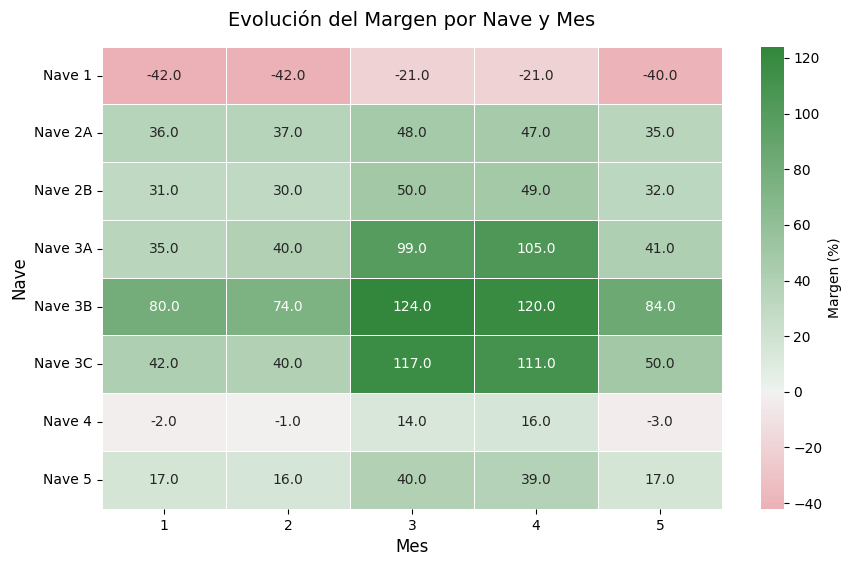

In [128]:
# 34
# 1. Convertimos los datos a formato matriz (Meses en filas, Naves en columnas)
df_pivot = df_nave_mens_beneficio.pivot_table(index='alias_nave', columns='mes', values='margen_nave_mes')

df_pivot.fillna(0)

# 2. Preparamos la figura
plt.figure(figsize=(10, 6))

# 3. Creamos una paleta divergente de rojo (hue=10) a verde (hue=130) pasando por el blanco
palette_rojo_verde = sns.diverging_palette(10, 130, s=80, l=50, as_cmap=True)

# 4. Dibujamos el mapa de calor
sns.heatmap(
    df_pivot,
    annot=True,            # Muestra el número dentro de cada celda
    fmt='.1f',             # Formato numérico (1 decimal; cámbialo a '.0f' si prefieres enteros)
    cmap=palette_rojo_verde, # Nuestra paleta rojo-blanco-verde
    center=0,              # Fuerza a que el punto neutro (blanco) esté exactamente en el 0
    linewidths=0.5,        # Líneas de separación sutiles entre celdas
    cbar_kws={'label': 'Margen (%)'}
)

plt.title('Evolución del Margen por Nave y Mes', fontsize=14, pad=15)
plt.xlabel('Mes', fontsize=12)
plt.ylabel('Nave', fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.show()

### El veredicto de dirección: El "efecto Empresa 3" (Nave 3A, Nave 3B y Nave 3C)

Tras presentar el mapa de calor a la dirección, la conclusión salta a la vista: la dependencia de los beneficios mensuales respecto a la **Empresa 3** es inmensa.

Sin embargo, la reacción del jefe va en otra dirección: como este cliente es el más grande y estable en su sector, asume que se le pueden subir los precios de transporte sin rechistar por el simple hecho de ser el peso pesado de la zona.

Para poner los datos sobre la mesa y evaluar el riesgo real, simulamos a continuación el mismo escenario pero **aislando el impacto de la Empresa 3**, evidenciando qué parte del beneficio real recae sobre sus hombros:

In [129]:
# 35
# Agrupación por mes
df_mes_con3=(
    df_nave_mens_beneficio
    .groupby(['mes'],as_index=False)
    .agg({
        'ingresos_nave_mes':'sum',
        'costes_nave_mes':'sum',
        'beneficio_nave_mes':'sum'
    })
)

# Se eliminan las naves 3_

empresa3=['Nave 3A','Nave 3B','Nave 3C']
df_empresa_nave_mes_sin3=df_nave_mens_beneficio[~df_nave_mens_beneficio['alias_nave'].isin(empresa3)]

# Se agrupa también para el caso en el que desapareciera la empresa 3
df_mes_sin3=(
    df_empresa_nave_mes_sin3
    .groupby(['mes'],as_index=False)
    .agg({
        'ingresos_nave_mes':'sum',
        'costes_nave_mes':'sum',
        'beneficio_nave_mes':'sum'
    })
)

# Unión de las dos tablas en una sola
df_comparativo=(
    df_mes_con3
    .merge(
        df_mes_sin3,
        on='mes',
        how='left',
        suffixes=('_con3','_sin3')
    )
)

# Cálculo del porcentaje de dependencia de la empresa 3
df_comparativo['porcentaje_dependencia'] = round((
    (
        df_comparativo['beneficio_nave_mes_con3']
        - df_comparativo['beneficio_nave_mes_sin3']
    )
    / df_comparativo['beneficio_nave_mes_con3']
) * 100,0)

df_comparativo=df_comparativo.rename(columns={'beneficio_nave_mes_con3':'beneficio_con3','beneficio_nave_mes_sin3':'beneficio_sin3'})


df_resultado_comparativo=df_comparativo[['mes','beneficio_con3','beneficio_sin3','porcentaje_dependencia']].copy()

df_resultado_comparativo.head()

,mes,beneficio_con3,beneficio_sin3,porcentaje_dependencia
0,1,996.59,281.63,72.0
1,2,924.09,279.68,70.0
2,3,1868.49,619.96,67.0
3,4,1936.09,679.89,65.0
4,5,1013.49,273.31,73.0


#**Bloque 3:** Modelado de escenarios y comparativa final

### La propuesta estratégica: Poniendo orden en la estructura de tarifas

Una vez que el análisis de dependencia hace reaccionar a la dirección y se toma conciencia del riesgo real, se abre la puerta para implantar un **modelo de tarificación sistemático y transparente**:

1. **Cuota fija por contenedor:** Se fija un alquiler base de **50 €/mes** por contenedor, asegurando la cobertura de costes fijos de inmovilizado.
2. **Tasa de transporte ajustada:** Se calcula en función del coste real por kilómetro recorrido en cada servicio, aplicando un **margen de beneficio mínimo (6%)**. En este sector, el transporte no debe ser la vía principal de rentabilidad, sino un servicio operativo equilibrado.
3. **Mecanismo de fidelización y compensación (Abono por Plástico):** Dado que la nueva tasa de transporte incrementará los costes para la Empresa 3, se demuestra con datos que la gran rentabilidad que nos aporta este cliente proviene de sus entregas de **plástico limpio/homogéneo**. Para evitar su fuga y neutralizar la subida del porte, proponemos aplicar una **bonificación/abono por kilogramo** en los contenedores que contengan exclusivamente plástico puro.

---

A continuación, ejecutamos las transformaciones y el modelado del nuevo escenario para evaluar el impacto global en la cuenta de resultados:

## Fase 1: Justificación del modelo, cálculo del incentivo y simulación del nuevo escenario

Para construir una solución sólida que no perjudique a nuestro mayor cliente (la Empresa 3) pero proteja nuestro margen, seguimos una línea de razonamiento basada en tres pasos analíticos:

```text
--- PASO 1: EVIDENCIA EMPÍRICA (La rentabilidad del plástico) ---
df_justificacion                 = Cruce granular enriquecido con el nombre del residuo
df_just_filtrado                 = Filtrado de ventana temporal (muestra de DIs de plástico puro)

--- PASO 2: CÁLCULO ANALÍTICO DEL INCENTIVO ---
df_plastico_puro                 = Filtrado exclusivo de flujos de plástico
Cálculo de 'x'                   = Determinación de la bonificación máxima por tonelada para asegurar un margen objetivo (65%)

--- PASO 3: SIMULACIÓN DEL NUEVO ESCENARIO ---
df2_beneficio_di_temp            = Aplicación condicional de la bonificación (0,008 €/kg en plástico puro)
df2_beneficio_di                 = Nuevo DataFrame granular con los costes e ingresos ajustados a la nueva estrategia

--- PASO 1: EVIDENCIA EMPÍRICA (La rentabilidad del plástico) ---

In [136]:
# 36
# Muestra de DIs en un intervalo determinado para evidenciar que la rentabilidad principal recae en los contenedores de plástico puro.

df_temp2=df_beneficio_di.merge(df_nave_poblacion,on='id_nave',how='left')

df_temp3=df_temp2[['id_viaje','n_di','fecha_traslado','id_nave','alias_nave','id_residuo','kg_netos_recibidos','beneficio_di','coste_gestion_di','ingreso_residuo']].copy()

df_residuos=residuos[['id_residuo','nombre']].copy()

df_temp4=df_temp3.merge(df_residuos,on='id_residuo',how='left')


df_justificacion=df_temp4[['id_viaje','n_di','fecha_traslado','id_nave','alias_nave','id_residuo','nombre','kg_netos_recibidos','beneficio_di','coste_gestion_di','ingreso_residuo']].copy()
df_justificacion['margen']=round(((df_justificacion['ingreso_residuo']-df_justificacion['coste_gestion_di'])/df_justificacion['ingreso_residuo'])*100,0)

df_just_filtrado=df_justificacion[df_justificacion['fecha_traslado'].between('2026-03-01','2026-03-07')]
display(df_just_filtrado.iloc[[0,1,4,5]])

,id_viaje,n_di,fecha_traslado,id_nave,alias_nave,id_residuo,nombre,kg_netos_recibidos,beneficio_di,coste_gestion_di,ingreso_residuo,margen
122,V-1085,280000222220260000123,2026-03-06,2,Nave 2A,3,carton mezcla,367,17.11,19.589644,36.70,47.0
123,V-1085,280000222220260000124,2026-03-06,2,Nave 2A,4,plastico mezcla,167,13.82,22.921943,36.74,38.0
144,V-1098,280000333320260000145,2026-03-03,4,Nave 3A,1,carton,608,44.57,16.226844,60.80,73.0
145,V-1099,280000333320260000146,2026-03-03,5,Nave 3B,2,plastico,931,140.93,63.893200,204.82,69.0


--- PASO 2: CÁLCULO ANALÍTICO DEL INCENTIVO ---

In [138]:
# 37
# Cálculo analítico de la bonificación máxima por tonelada para mantener un margen objetivo del 65% en los flujos de plástico.

df_plastico_puro=df_justificacion.query('nombre=="plastico"').copy()
df_plastico_puro['coste_tn']=(df_plastico_puro['coste_gestion_di']/df_plastico_puro['kg_netos_recibidos'])*1000
df_plastico_puro['ingreso_tn']=(df_plastico_puro['ingreso_residuo']/df_plastico_puro['kg_netos_recibidos'])*1000

#como el precio del plastico no ha cambiado a lo largo del periodo de estudio, se cogen los datos de una sola fila

primera_fila = df_plastico_puro.iloc[0]

ingresos = primera_fila['ingreso_tn']   # 220 €
costes = primera_fila['coste_tn']         # 68.29 €

margen_objetivo = 0.65

x = ingresos - costes - (ingresos * margen_objetivo)

print(f"Bonificación máxima por tonelada 'x' para un {margen_objetivo*100}% de margen: {x:.2f} € por tonelada")

Bonificación máxima por tonelada 'x' para un 65.0% de margen: 8.71 € por tonelada


--- PASO 3: SIMULACIÓN DEL NUEVO ESCENARIO ---


In [139]:
# 38
# Generación del nuevo escenario (df2_beneficio_di) aplicando el abono por kg exclusivamente a los residuos de plástico puro.
df2_beneficio_di_temp=df_justificacion.copy()

df2_beneficio_di_temp['bonificacion']=np.where(df2_beneficio_di_temp['nombre']=='plastico',df2_beneficio_di_temp['kg_netos_recibidos']*0.008,0)

df2_beneficio_di_temp['coste_di2']=df2_beneficio_di_temp['coste_gestion_di']+df2_beneficio_di_temp['bonificacion']

df2_beneficio_di_temp['beneficio_di2']=df2_beneficio_di_temp['ingreso_residuo']-df2_beneficio_di_temp['coste_di2']

df2_beneficio_di=df2_beneficio_di_temp[['id_viaje','n_di','fecha_traslado','id_nave','alias_nave','id_residuo','nombre','kg_netos_recibidos','ingreso_residuo','coste_di2','beneficio_di2']].copy()

display(df2_beneficio_di.query('nombre=="plastico"').head())

,id_viaje,n_di,fecha_traslado,id_nave,alias_nave,id_residuo,nombre,kg_netos_recibidos,ingreso_residuo,coste_di2,beneficio_di2
27,V-1017,280000333320260000028,2026-01-04,5,Nave 3B,2,plastico,891,196.02,67.970571,128.049429
28,V-1018,280000333320260000029,2026-01-28,5,Nave 3B,2,plastico,888,195.36,67.741714,127.618286
29,V-1019,280000333320260000030,2026-01-20,5,Nave 3B,2,plastico,867,190.74,66.139714,124.600286
30,V-1020,280000333320260000031,2026-01-26,5,Nave 3B,2,plastico,811,178.42,61.867714,116.552286
86,V-1058,280000333320260000087,2026-02-13,5,Nave 3B,2,plastico,897,197.34,68.428286,128.911714


## Fase 2: Recálculo de costes logísticos y tarificación del servicio de transporte

En esta fase trasladamos la nueva estrategia a nivel de viaje (`id_viaje`). Para evitar un incremento desmedido en las tarifas de portes que ponga en riesgo la relación con el cliente, se analiza el coste medio por kilómetro y se ajusta la fórmula sobre la distancia operativa real:

```text
--- PASO 1: CONSOLIDACIÓN POR VIAJE ---
df2_grupo_viaje                  = Agrupación de df2_beneficio_di a nivel de id_viaje

--- PASO 2: ANÁLISIS DE COSTES UNITARIOS Y TARIFA ---
df2_viaje_comp['coste_km']       = Estimación del coste medio por kilómetro operativo
Ingreso_km                       = Tasa teórica estimada por km (margen base del 6%)

--- PASO 3: INTEGRACIÓN Y AJUSTE COMERCIAL DE PORTES ---
viaje2_gastos_cobros             = Merge de datos logísticos (total_km y coste_viaje)
ingreso_viaje2 / beneficio_viaje2 = Cálculo del ingreso y beneficio real por viaje sobre trayecto simple

--- PASO 1: CONSOLIDACIÓN POR VIAJE ---

---



In [140]:
# 39
# Agrupación por viaje

df2_grupo_viaje=(
    df2_beneficio_di
    .groupby('id_viaje',as_index=False)
    .agg({
        'fecha_traslado':'first',
        'id_nave':'first',
        'alias_nave':'first',
        'coste_di2':'sum',
        'ingreso_residuo':'sum',
        'beneficio_di2':'sum'

    })
)

--- PASO 2: ANÁLISIS DE COSTES UNITARIOS Y TARIFA ---

In [141]:
# 40
# Estimación del coste operativo medio por kilómetro a partir de los datos históricos.

df2_viaje_comp=df_viaje_poblacion[['id_viaje','fecha_traslado','id_nave','coste_viaje','total_km']].copy()

df2_viaje_comp['coste_km']=df2_viaje_comp['coste_viaje']/df2_viaje_comp['total_km']

df2_viaje_comp['coste_km'].mean()

In [143]:
# 41
# Cálculo de la tarifa teórica por km aplicando un margen base del 6% sobre el coste medio.
Ingreso_km=df2_viaje_comp['coste_km'].mean()/(1-0.06)
print(f"ingreso medio por kilómetro de distancia= {Ingreso_km:.2f} euros")

ingreso medio por kilómetro de distancia= 1.03 euros


In [145]:
# 41
df2_viaje_poblacion=df_viaje_poblacion[['id_viaje','total_km','coste_viaje']].copy()

--- PASO 3: INTEGRACIÓN Y AJUSTE COMERCIAL DE PORTES ---

In [146]:
# 42
# Integración de los datos de distancia (total_km) y coste operativo (coste_viaje) en el dataset agrupado.
viaje2_gastos_cobros=(
    df2_grupo_viaje.merge(
        df2_viaje_poblacion,
        on='id_viaje',
        how='left',
        indicator=True
    )
)
print(viaje2_gastos_cobros['_merge'].value_counts())


_merge
both          207
left_only       0
right_only      0
Name: count, dtype: int64


In [147]:
# 42
viaje2_gastos_cobros=viaje2_gastos_cobros.drop(columns='_merge')

In [148]:
#43
# Cálculo del ingreso real por servicio (ingreso_viaje2).
# Criterio comercial: Aplicamos la tarifa sobre la distancia de ida de trayecto único
# (descontando 2 km de maniobras y dividiendo por 2) para mantener la competitividad de las tarifas.

viaje2_gastos_cobros['ingreso_viaje2']=Ingreso_km*(viaje2_gastos_cobros['total_km']-2)/2
viaje2_gastos_cobros['beneficio_viaje2']=viaje2_gastos_cobros['ingreso_viaje2']-viaje2_gastos_cobros['coste_viaje']

## Fase 3: Consolidación mensual, mapa de calor del nuevo escenario y comparativa global

Para culminar el proyecto, este último bloque eleva los datos a nivel estratégico mensual por nave, visualiza la nueva distribución de márgenes y enfrenta cara a cara ambos escenarios:

```text
--- APARTADO 1: CONSOLIDACIÓN MENSUAL Y POR NAVE ---
df2_beneficio_viaje             = Extracción del mes e integración de variables a nivel de viaje
df2_grupo_mes_nave              = Agrupación por [mes, id_nave] + cruce con número de contenedores
df2_nave_mes_beneficio          = Cálculo final de ingresos, costes, beneficios y margen por nave y mes

--- APARTADO 2: VISUALIZACIÓN DE MÁRGENES ---
mapa_calor_nuevo_escenario      = Generación del mapa de calor con la rentabilidad optimizada

--- APARTADO 3: COMPARATIVA GLOBAL DE ESCENARIOS ---
df2_mensual                     = Agregación del resultado global mensual del nuevo modelo
df2_comparativo                 = Merge con el escenario anterior y renombrado de columnas para la comparativa final (gráfico de barras)

###--- APARTADO 1: CONSOLIDACIÓN MENSUAL Y POR NAVE ---

In [150]:
# 44
viaje2_gastos_cobros['mes']=viaje2_gastos_cobros['fecha_traslado'].dt.month

df2_beneficio_viaje=viaje2_gastos_cobros[['id_viaje','fecha_traslado','mes','id_nave','alias_nave','coste_di2','ingreso_residuo','beneficio_di2','coste_viaje','ingreso_viaje2','beneficio_viaje2']].copy()

In [151]:
# 45
# Agrupación por mes y nave

grupo_mes_nave=(
    df2_beneficio_viaje
    .groupby(['mes','id_nave','alias_nave'],as_index=False)
    .agg({
        'coste_di2':'sum',
        'ingreso_residuo':'sum',
        'beneficio_di2':'sum',
        'coste_viaje':'sum',
        'ingreso_viaje2':'sum',
        'beneficio_viaje2':'sum'

    })
)

# Incorporación del número de contenedores de cada nave
cobros_contenedores=cobros[['id_nave','num_contenedores']].copy()

df2_grupo_mes_nave=grupo_mes_nave.merge(cobros_contenedores,on='id_nave',how='left',indicator=True)

print(df2_grupo_mes_nave['_merge'].value_counts())

_merge
both          40
left_only      0
right_only     0
Name: count, dtype: int64


In [153]:
# 46
# Cálculo integral de la cuenta de resultados por nave y mes bajo el nuevo modelo:
# ingresos por alquiler (50 €/contenedor), costes operativos, beneficio neto y margen porcentual.

df2_grupo_mes_nave['ingreso2_alquiler']=df2_grupo_mes_nave['num_contenedores']*50

df2_grupo_mes_nave['ingresos2_nave_mes']=df2_grupo_mes_nave['ingreso_residuo']+df2_grupo_mes_nave['ingreso_viaje2']+df2_grupo_mes_nave['ingreso2_alquiler']

df2_grupo_mes_nave['costes2_nave_mes']=df2_grupo_mes_nave['coste_di2']+df2_grupo_mes_nave['coste_viaje']

df2_grupo_mes_nave['beneficio2_nave_mes']=round(
    df2_grupo_mes_nave['ingresos2_nave_mes']-
    df2_grupo_mes_nave['costes2_nave_mes'],2
)

df2_grupo_mes_nave['margen2_mes']=round(((df2_grupo_mes_nave['ingresos2_nave_mes']-df2_grupo_mes_nave['costes2_nave_mes'])/df2_grupo_mes_nave['ingresos2_nave_mes'])*100,0)

df2_nave_mes_beneficio=df2_grupo_mes_nave[['mes','id_nave','alias_nave','ingresos2_nave_mes','costes2_nave_mes','beneficio2_nave_mes','margen2_mes']].copy()

###--- APARTADO 2: VISUALIZACIÓN DE MÁRGENES ---

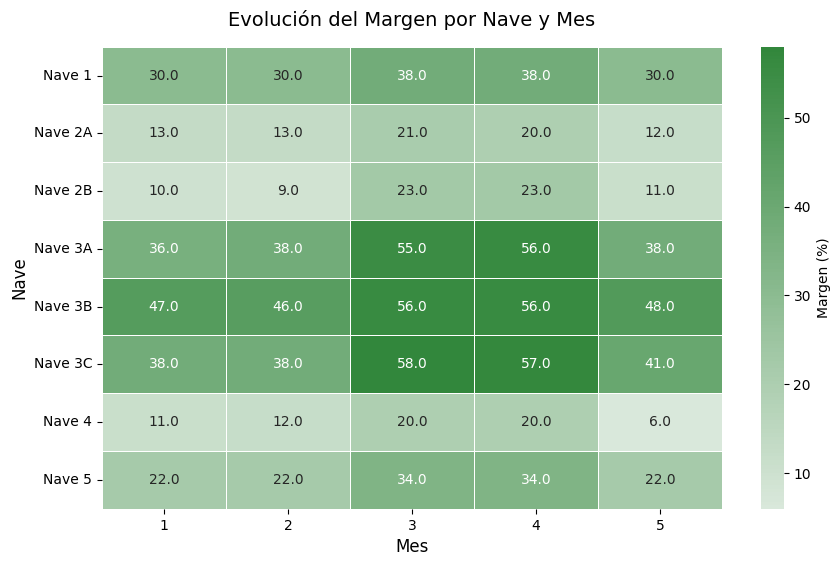

In [154]:
# 47
# 1. Convertimos los datos a formato matriz (Meses en filas, Naves en columnas)
df2_pivot = df2_nave_mes_beneficio.pivot_table(index='alias_nave', columns='mes', values='margen2_mes')

df2_pivot.fillna(0)

# 2. Preparamos la figura
plt.figure(figsize=(10, 6))

# 3. Creamos una paleta divergente de rojo (hue=10) a verde (hue=130) pasando por el blanco
palette_rojo_verde = sns.diverging_palette(10, 130, s=80, l=50, as_cmap=True)

# 4. Dibujamos el mapa de calor
sns.heatmap(
    df2_pivot,
    annot=True,            # Muestra el número dentro de cada celda
    fmt='.1f',             # Formato numérico (1 decimal; cámbialo a '.0f' si prefieres enteros)
    cmap=palette_rojo_verde, # Nuestra paleta rojo-blanco-verde
    center=0,              # Fuerza a que el punto neutro (blanco) esté exactamente en el 0
    linewidths=0.5,        # Líneas de separación sutiles entre celdas
    cbar_kws={'label': 'Margen (%)'}
)

plt.title('Evolución del Margen por Nave y Mes', fontsize=14, pad=15)
plt.xlabel('Mes', fontsize=12)
plt.ylabel('Nave', fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.show()

###--- APARTADO 3: COMPARATIVA GLOBAL DE ESCENARIOS ---

In [155]:
# 48
# Agregación de resultados a escala global mensual

df2_mensual=(
    df2_nave_mes_beneficio
    .groupby(['mes'],as_index=False)
    .agg({
        'ingresos2_nave_mes':'sum',
        'costes2_nave_mes':'sum',
        'beneficio2_nave_mes':'sum'
    })
)

# Cruce con el escenario anterior (df_mes_con3)
# para evaluar el impacto real de la nueva estrategia.

df2_comparativo=(
    df2_mensual
    .merge(df_mes_con3,on='mes',how='left',indicator=True)
)
print(df2_comparativo['_merge'].value_counts())

_merge
both          5
left_only     0
right_only    0
Name: count, dtype: int64


In [156]:
#49
# Normalización y renombrado de columnas para exponer claramente el 'beneficio_escenario_actual' frente al 'beneficio_escenario_sugerido'.

df2_comparativo=df2_comparativo.rename(columns={'beneficio2_nave_mes':'beneficio_escenario_sugerido','beneficio_nave_mes':'beneficio_escenario_actual'})


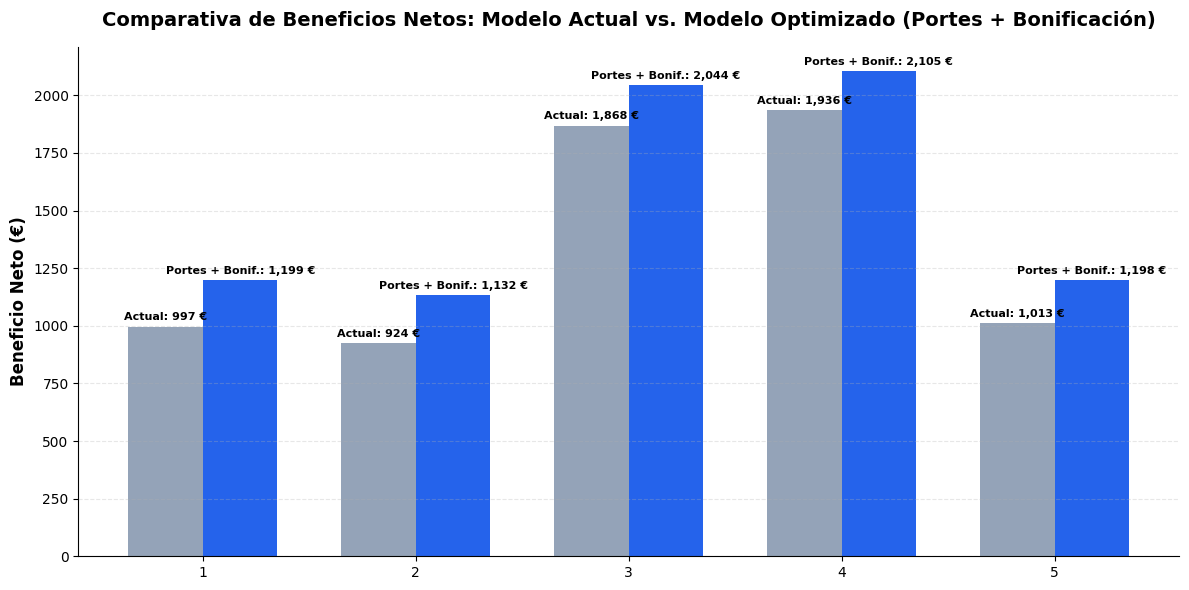

In [157]:
# 50
# Definimos los datos de los meses y de ambos escenarios a partir de tu tabla
meses = df2_comparativo['mes'].tolist()
beneficio_1 = df2_comparativo['beneficio_escenario_actual'].tolist()
beneficio_3 = df2_comparativo['beneficio_escenario_sugerido'].tolist()

x = np.arange(len(meses))  # Localizaciones de las barras
width = 0.35               # Ancho de las barras

fig, ax = plt.subplots(figsize=(12, 6))

# Dibujamos las barras
barras1 = ax.bar(x - width/2, beneficio_1, width, label='Escenario 1', color='#94a3b8') # Gris neutro para datos actuales
barras2 = ax.bar(x + width/2, beneficio_3, width, label='Escenario 3', color='#2563eb') # Azul directo para el nuevo modelo

# Configuramos los ejes y títulos pensando en dirección (números claros)
ax.set_ylabel('Beneficio Neto (€)', fontsize=12, fontweight='bold')
ax.set_title('Comparativa de Beneficios Netos: Modelo Actual vs. Modelo Optimizado (Portes + Bonificación)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(meses, fontsize=10)

# Ocultamos la leyenda tradicional porque el jefe de la vieja escuela se marea con ella;
# preferimos etiquetar directamente las barras.

# Añadimos etiquetas de texto encima de cada barra para ver los números al instante
def autolabel(rects, texto_personalizado=None):
    for i, rect in enumerate(rects):
        height = rect.get_height()
        # Si pasamos una etiqueta personalizada por barra (para el escenario 3)
        label = texto_personalizado[i] if texto_personalizado else f"{height:,.0f} €"
        ax.annotate(
            label,
            xy=(rect.get_x() + rect.get_width() / 2, height),
            xytext=(0, 3),  # Desplazamiento vertical de 3 puntos
            textcoords="offset points",
            ha='center', va='bottom', fontsize=8, fontweight='semibold'
        )

# Etiquetas para el Escenario 1 (Datos actuales)
autolabel(barras1, [f"Actual: {val:,.0f} €" for val in beneficio_1])

# Etiquetas para el Escenario 3 (Portes + bonificación implícita, directo a beneficio)
autolabel(barras2, [f"Portes + Bonif.: {val:,.0f} €" for val in beneficio_3])

# Limpieza visual del gráfico
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()